In [1]:
import sys
sys.path.insert(0, "/home/s232534/scripts")

import pandas as pd
import matplotlib.pyplot as plt
from exploration import functions
import numpy as np

In [3]:
# Load and filter:

df_stats = pd.read_csv("/home/s232534/data/stats_071125/statistical_summary_071125.csv") 
df_map_matching = pd.read_csv("/home/s232534/scripts/map_matching/map_matching_percentages.csv") 
#df_percentile_map = pd.read_parquet("/home/s232534/data/percentile_pipeline/percentiles_071125.parquet")

# ---
# Drop modes we will not be using for this thesis and modes to merge and remap:
# ---
modes_to_drop = ['OTHER', 'PLANE', 'ON_DEMAND', 'ELECT_BIKE', 'ELECT_SCOOTER', 'TWO_WHEELER']  
mode_remap = {
    'PRIV_CAR_DRIVER': 'CAR',
    'PRIV_CAR_PASSENGER': 'CAR',
    'LIGHT_COMM_VEHICLE': 'CAR',
    'TAXI': 'CAR',
    'TRAIN_EXPRESS': 'TRAIN'
}

df_stats = functions.remap_and_drop_modes_df(df_stats, mode_remap, modes_to_drop)
df_map_matching = functions.remap_and_drop_modes_df(df_map_matching, mode_remap, modes_to_drop)
#df_percentile_map = functions.remap_and_drop_modes_df(df_percentile_map, mode_remap, modes_to_drop)

# ---
# Filter by speed avg
# ---
threshold: dict = { 
            "WALKING": 6.5, # under 25 km/h
            "BIKE": 10, # 36 km/h
            "CAR": 39,
            "BUS": 14,  # ~50 km/h      
            "TRAMWAY": 19.5,     # ~70 km/h
            "SUBWAY": 11.1, # 40 km/h
            "TRAIN": 61,  # ~ 220 km/h     
        }

df_stats = functions.filter_motion_data_speed_avg(df_stats, threshold)

# ---
# Filter temporal data
# ---
df_stats = functions.filter_temporal_data(df_stats, time_thres=180)

# Propogate the filters down to the map matching df:
keep_ids = set(df_stats['TRIP_KEY'])
df_map_matching = df_map_matching[df_map_matching['KEY'].isin(keep_ids)].copy()

# --- 
# Sanity Checks: (should return True and True)
# --- 
print(len(df_stats) == len(df_map_matching))
print(sorted(df_stats['TRIP_KEY']) == sorted(df_map_matching['KEY']))

# ---
# Split it out by modality
# ---

# Uni-modal ONLY.
df_stats_s = df_stats.loc[~df_stats['MULTI_MODAL']] 
df_map_matching_s = df_map_matching.loc[~df_map_matching['MULTI_MODAL']] 

# Multi-modal
df_stats_m = df_stats.loc[df_stats['MULTI_MODAL']] 
df_map_matching_m = df_map_matching.loc[df_map_matching['MULTI_MODAL']] 


At WALKING threshold 6.5; 84 are above.
At BIKE threshold 10; 7 are above.
At CAR threshold 39; 8 are above.
At BUS threshold 14; 15 are above.
At TRAMWAY threshold 19.5; 0 are above.
At SUBWAY threshold 11.1; 24 are above.
At TRAIN threshold 61; 8 are above.
Filtered by TOTAL_TIME > 180. Dropped 4705 rows.
True
True


## Single Modal visualisation

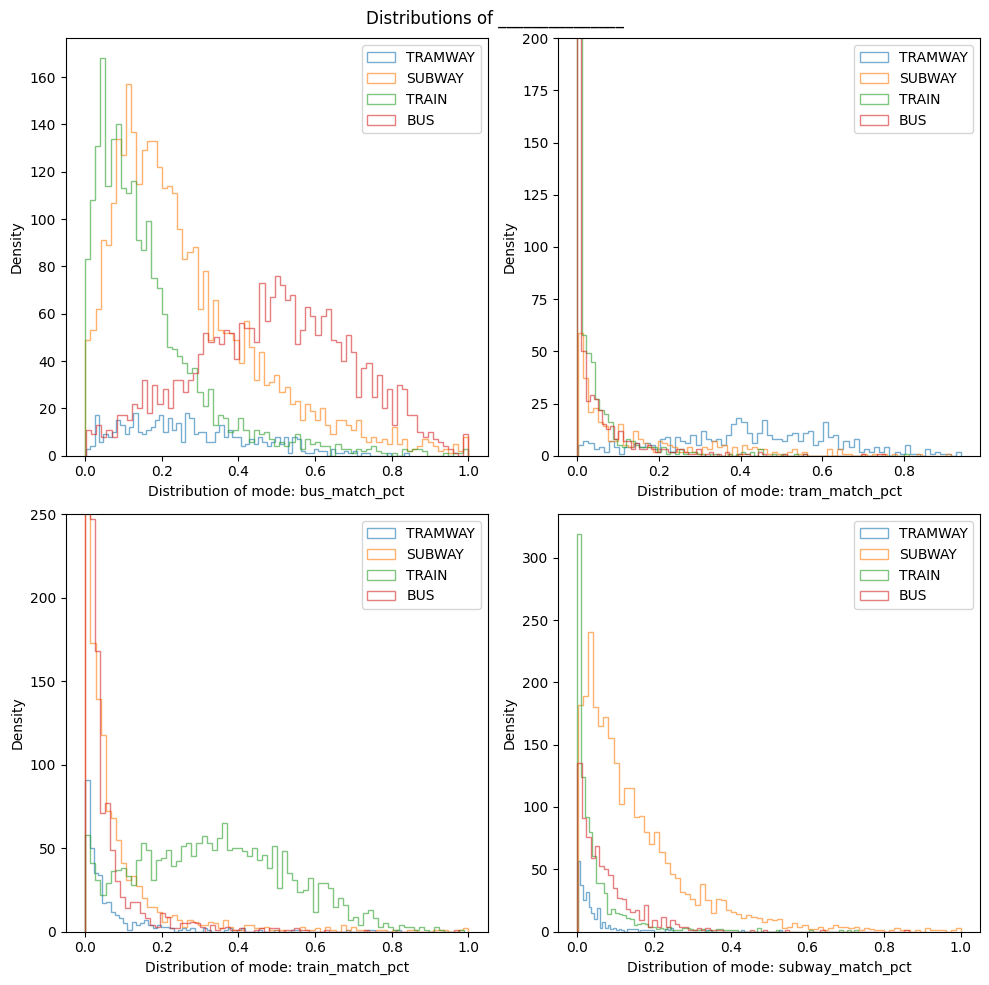

In [5]:
fig, axes = functions.plot_hist_mode_2x2(df=df_map_matching_s, modes=['TRAMWAY', 'SUBWAY', 'TRAIN' ,'BUS'], cols=['bus_match_pct','tram_match_pct','train_match_pct','subway_match_pct'], bin_num=75, PROB_DENSITY=False)
#axes[1, 0].set_xlim(200, 400)
axes[1, 0].set_ylim(0, 250)
axes[0, 1].set_ylim(0, 200)
plt.show()

## Multi-modal visualisation

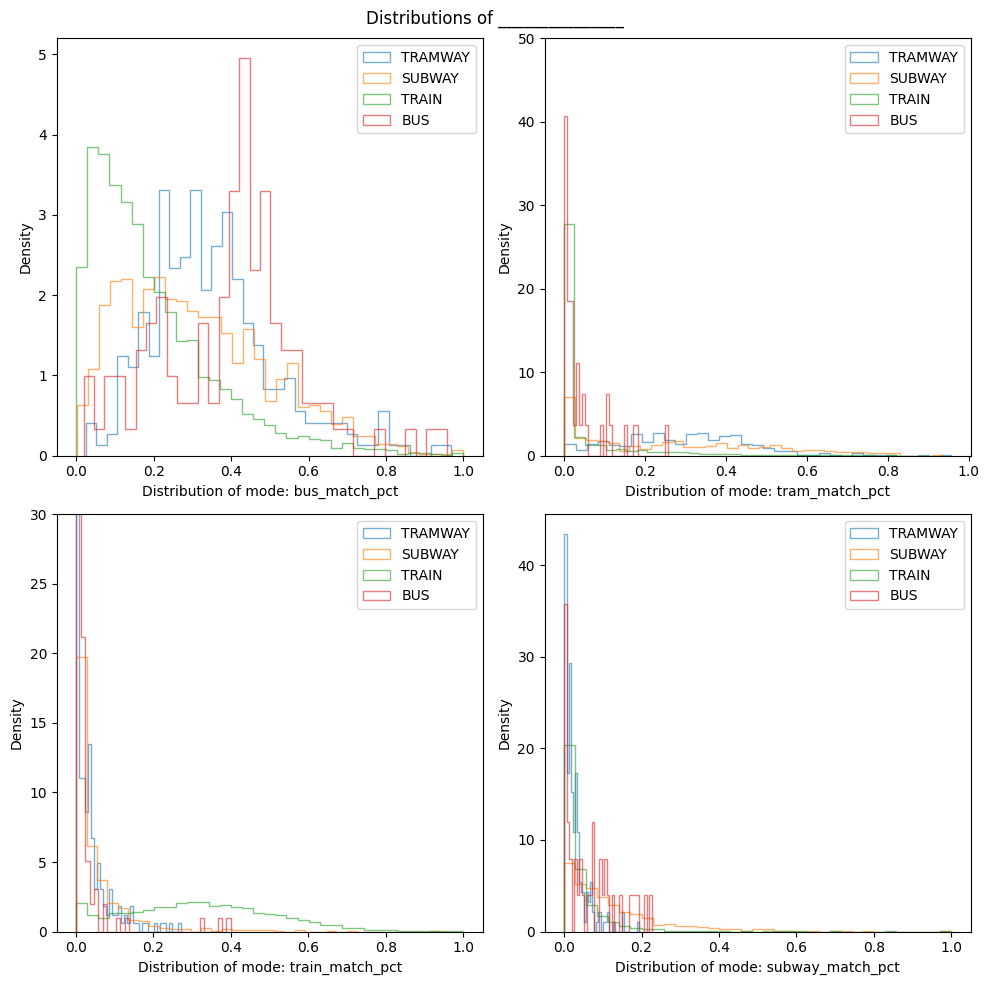

In [6]:
fig, axes = functions.plot_hist_mode_2x2(df=df_map_matching_m, modes=['TRAMWAY', 'SUBWAY', 'TRAIN' ,'BUS'], cols=['bus_match_pct','tram_match_pct','train_match_pct','subway_match_pct'], bin_num=35, PROB_DENSITY=True)
axes[1, 0].set_ylim(0, 30)
axes[0, 1].set_ylim(0, 50)

plt.show()

# Map-matching signal generation

In [7]:
import geopandas as gpd
import routes

df_stats = pd.read_csv("/home/s232534/data/stats_071125/statistical_summary_071125.csv", usecols=["TRIP_KEY", "MULTI_MODAL", "MAIN_MODE"])
gps_trace = functions.filter_mode_random(df_stats, 'BUS')

print("Loading route parquet files...")
bus_routes = gpd.read_parquet("/home/s232534/scripts/map_matching/osm_routes/bus_routes.parquet")

bus_arr = routes.bind_route_geometry_to_id(bus_routes)
BALLTREE_BUS = routes.generate_balltree_obj(bus_arr)

matched_bus = routes.fast_match(bus_arr, gps_trace, BALLTREE_BUS, 20)

Trip key being sampled = 42_0167-tuesday-44873-1
Loading route parquet files...


In [8]:
signal = routes.generate_route_signal(matched_bus, bus_arr, gps_trace, BALLTREE_BUS, 20, verbose=True)

ID: 5846507111 with a match percentage of (np.int64(357), np.float64(0.422)) is being used.


In [9]:
signal

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

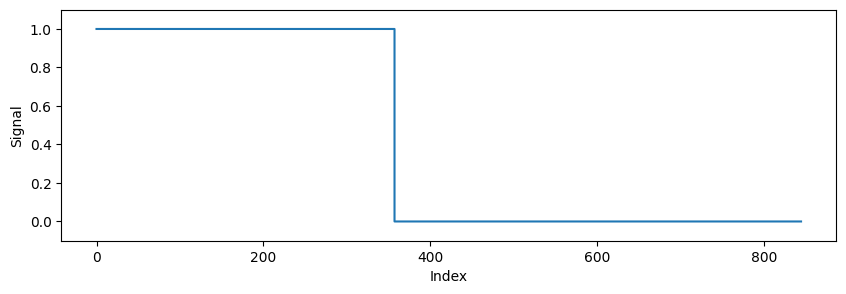

In [10]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 3))
plt.step(np.arange(len(signal)), signal, where="post")
plt.ylim(-0.1, 1.1)
plt.xlabel("Index")
plt.ylabel("Signal")
plt.show()

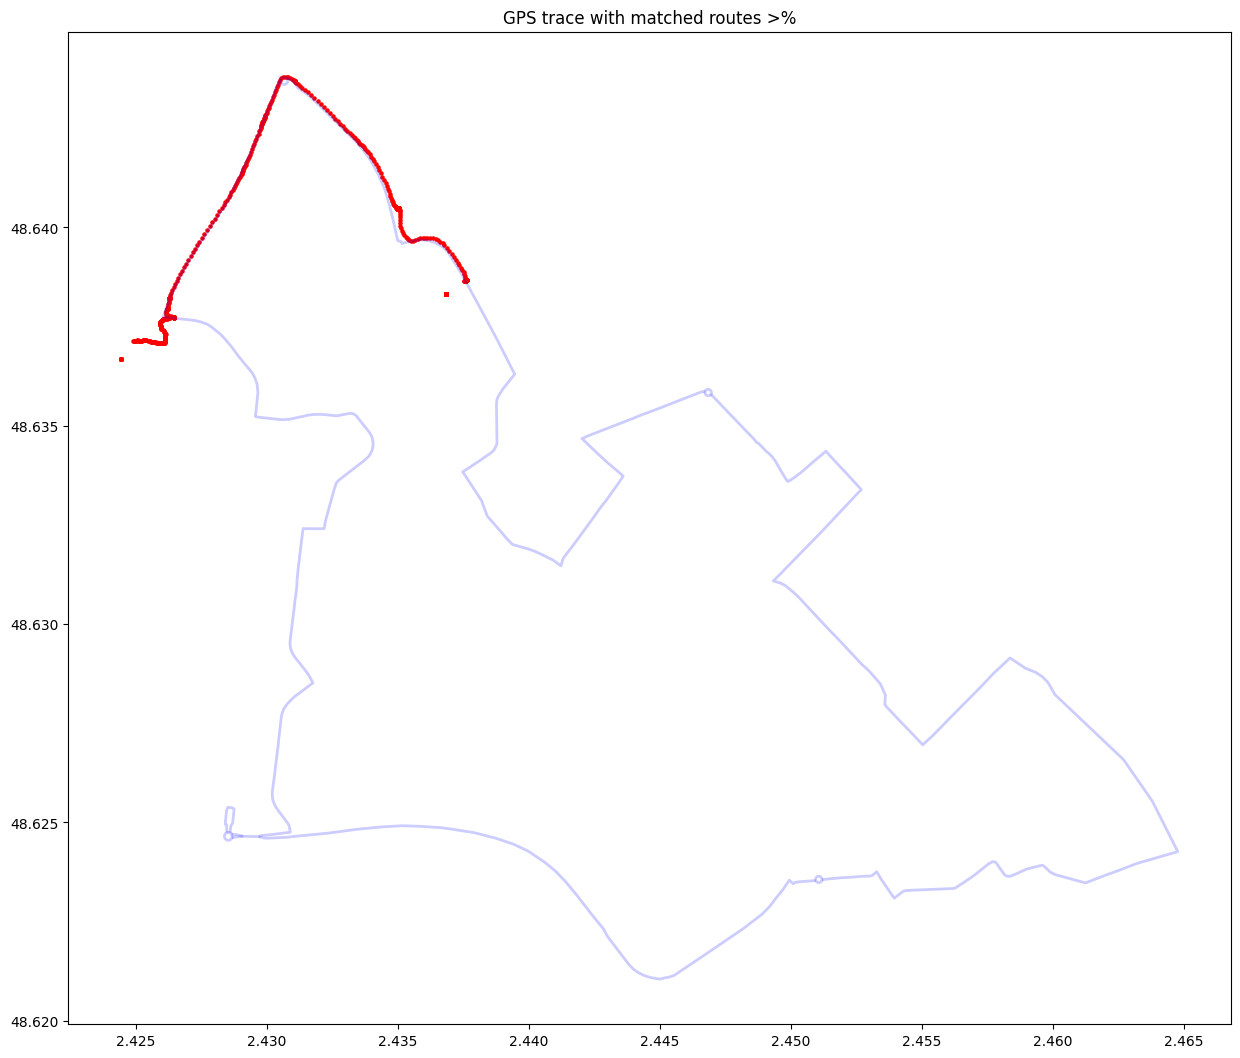

In [11]:
routes.visualise_top_route_ids(gps_trace, bus_routes, [5846507111])

# Densifcation for Match-accuracy increase:

In [10]:
from shapely.ops import linemerge
from shapely.geometry import Point, MultiLineString, LineString

# Simple interpolate.
def interpolate_route(route_geom, spacing):
    def sample(line):
        if line.length == 0:
            return [Point(line.coords[0])] if len(line.coords) else []
        dists = np.arange(0, line.length + spacing, spacing)
        return [line.interpolate(d) for d in dists]

    if isinstance(route_geom, LineString):
        return sample(route_geom)

    if isinstance(route_geom, MultiLineString):
        merged = linemerge(route_geom)  # may become LineString or stay MultiLineString
        if isinstance(merged, LineString):
            return sample(merged)
        out = []
        for ls in merged.geoms:
            out.extend(sample(ls))
        return out

    return []

In [11]:
import numpy as np
from shapely.geometry import LineString, MultiLineString
from shapely.ops import linemerge

def densify_line(line: LineString, spacing: float) -> LineString:
    length = line.length
    if length == 0:
        return line

    # number of segments --- spacing <= desired spacing
    n_seg = max(1, int(np.ceil(length / spacing)))
    dists = np.linspace(0, length, n_seg + 1)
    pts = [line.interpolate(d) for d in dists]
    
    return LineString(pts)

def densify_geom(geom, spacing: float):
    """
    Densify LineString / MultiLineString geometry.
    Expects CRS in *meters* (metric).
    """
    if geom.is_empty:
        return geom

    if isinstance(geom, LineString):
        return densify_line(geom, spacing)

    if isinstance(geom, MultiLineString):
        parts = []
        for part in geom.geoms:
            dense = densify_line(part, spacing)
            parts.append(dense)
        return MultiLineString(parts)

    # Fallback if it is neither...just return the same geom
    return geom

import geopandas as gpd

def add_densified_geometry(routes_gdf: gpd.GeoDataFrame, spacing_m: int, metric_crs=3857):
    """
    routes_gdf: GeoDataFrame with OSM route geometries (EPSG:4326 as per OSM data).
    spacing_m : desired spacing between points in meters.
    
    Returns: new GeoDataFrame with an extra 'geometry_dense' column.
    """
    routes = routes_gdf.copy() # We ensure a copy of the original routes df. This might not be mem efficient...

    # project to metric CRS
    routes_metric = routes.to_crs(metric_crs)

    # densify geometry while in metric CRS
    routes_metric["geometry_dense"] = routes_metric["geometry"].apply(lambda g: densify_geom(g, spacing_m))

    # project densified geometry back to original CRS 
    routes["geometry_dense"] = routes_metric["geometry_dense"].to_crs(routes_gdf.crs) # <- Could overwrite orig col to save memory.

    return routes


In [14]:
bus_routes_interpolated = add_densified_geometry(bus_routes, 10)

In [99]:
bus_routes_interpolated

,route,name,operator,id,timestamp,version,tags,osm_type,geometry,ref,changeset,geometry_dense
0,bus,A,Transdev,1133251312,1695756687,2,"{""visible"":false,""public_transport:version"":""2""}",way,"MULTILINESTRING ((2.96579 48.39857, 2.96526 48...",None,NaN,"MULTILINESTRING ((2.96579 48.39857, 2.96572 48..."
1,bus,Bus 414D : Évry-Courcouronnes Centre → Vert-le...,Keolis Tice,6677848,1701637048,83,"{""colour"":""#F094BB"",""from"":""\u00C9vry-Courcour...",relation,"MULTILINESTRING ((2.37097 48.59545, 2.37086 48...",414D,0.0,"MULTILINESTRING ((2.37097 48.59545, 2.3709 48...."
2,bus,Bus G'bus : Goussainville RER (Circulaire),Keolis Roissy Pays de France Ouest,29006204,1691658932,59,"{""colour"":""#F4A8BC"",""from"":""Goussainville RER""...",relation,"MULTILINESTRING ((2.45024 49.03015, 2.45024 49...",G'bus,0.0,"MULTILINESTRING ((2.45024 49.03015, 2.45024 49..."
3,bus,Bus 30B (circulaire) : Goussainville RER D -> ...,Keolis Roissy Pays de France Ouest,29220913,1690972353,65,"{""colour"":""#00BDF3"",""from"":""Goussainville RER ...",relation,"MULTILINESTRING ((2.45362 49.02987, 2.45367 49...",30B,0.0,"MULTILINESTRING ((2.45362 49.02987, 2.45367 49..."
4,bus,Bus 32A : Goussainville La Charmeuse - Aulnay-...,Keolis CIF,29435626,1694685998,98,"{""colour"":""#B2CE40"",""from"":""Goussainville - La...",relation,"MULTILINESTRING ((2.46247 49.02638, 2.46244 49...",32A,0.0,"MULTILINESTRING ((2.46247 49.02638, 2.46243 49..."
...,...,...,...,...,...,...,...,...,...,...,...,...
3230,bus,Ligne G2 : Gare Orry-Coye → Lamorlaye,Oise Mobilité,53740055174,1702983239,20,"{""colour"":""#E5BA39"",""from"":""Gare Orry-Coye"",""n...",relation,"LINESTRING (2.45618 49.1432, 2.45073 49.14342,...",G2,0.0,"LINESTRING (2.45618 49.1432, 2.4561 49.14321, ..."
3231,bus,Ligne G2 : Lamorlaye → Gare Orry-Coye,Oise Mobilité,53756868607,1702983239,14,"{""colour"":""#E5BA39"",""from"":""Lamorlaye"",""networ...",relation,"MULTILINESTRING ((2.42868 49.14952, 2.42858 49...",G2,0.0,"MULTILINESTRING ((2.42868 49.14952, 2.42859 49..."
3232,bus,Ligne N1 : circulaire de Lamorlaye,Oise Mobilité,53773683463,1702983239,20,"{""colour"":""#B0CA53"",""from"":""Ch\u00E2teau"",""net...",relation,"LINESTRING (2.42868 49.14952, 2.42858 49.1495,...",N1,0.0,"LINESTRING (2.42868 49.14952, 2.42859 49.1495,..."
3233,bus,Bus TIM - Boucle Bords de Seine,RATP,59421875984,1703880497,3,"{""colour"":""#98d4e2"",""from"":""Gare de Bellevue"",...",relation,"MULTILINESTRING ((2.22944 48.81894, 2.22957 48...",TIM,0.0,"MULTILINESTRING ((2.22944 48.81894, 2.22953 48..."


Before densification:

- We can see that it is very sparse in some areas!

In [16]:
bus_routes_interpolated.iloc[810]

route                                                           bus
name                               La Traverse Batignolles - Bichat
operator                                                       RATP
id                                                      14233687173
timestamp                                                1702947763
version                                                          61
tags              {"colour":"#4B2795","from":"Porte de Saint-Oue...
osm_type                                                   relation
geometry          MULTILINESTRING ((2.3215057849884033 48.884571...
ref                                                     La Traverse
changeset                                                       0.0
geometry_dense    MULTILINESTRING ((2.3215057849884033 48.884571...
Name: 810, dtype: object

Text(0.5, 1.0, 'Isolated route geometry point coordinates')

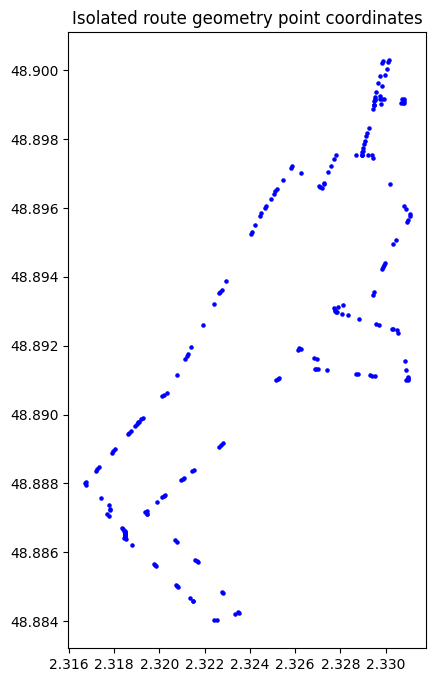

In [17]:
#route_geom = bus_routes[bus_routes['id'] == 14845997708].geometry.iloc[0]
ridx = 810
route_geom = bus_routes_interpolated['geometry'].iloc[ridx]

route_points = []
if isinstance(route_geom, LineString):
    route_points = [Point(x, y) for x, y in route_geom.coords]
elif isinstance(route_geom, MultiLineString):
    for line in route_geom.geoms:
        route_points.extend(Point(x, y) for x, y in line.coords)

gdf_route_pts = gpd.GeoDataFrame(geometry=route_points, crs="EPSG:4326")

ax = gdf_route_pts.plot(figsize=(8, 8), color="blue", markersize=5)
#gdf_trace.plot(ax=ax, color="red", markersize=5)

ax.set_title("Isolated route geometry point coordinates")

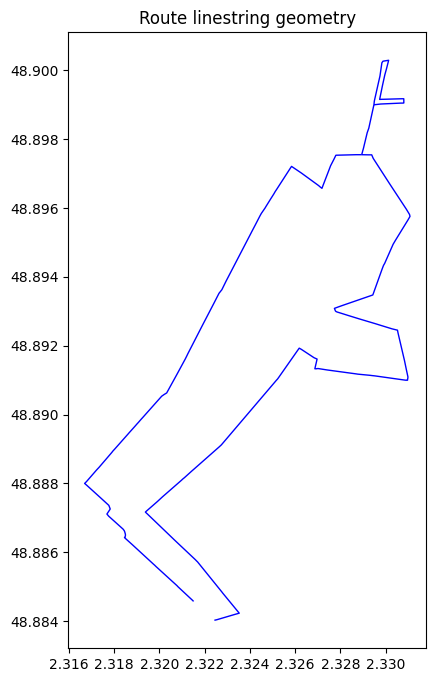

In [18]:
# Displaying how it looks as actual geometry!
fig, ax = plt.subplots(figsize=(8, 8))
gpd.GeoSeries([route_geom], crs=bus_routes_interpolated.crs).plot(ax=ax, edgecolor="blue", linewidth=1)
ax.set_title(f"Route linestring geometry")
plt.show()

### Using simple interpolation

Text(0.5, 1.0, 'GPS trace (red) vs route points (blue)')

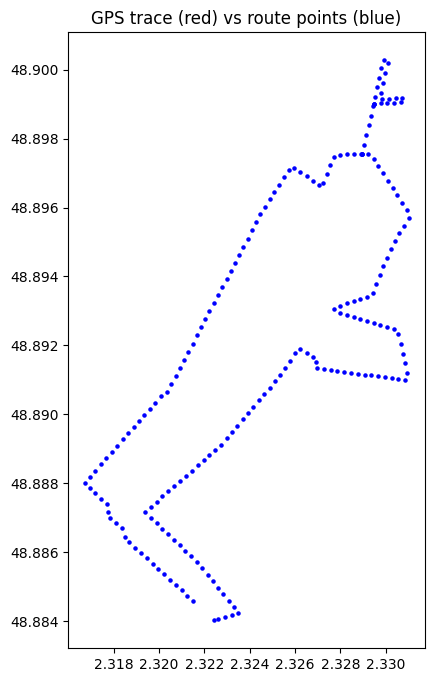

In [19]:
new_line = interpolate_route(route_geom, 0.0003)
#gdf_route_pts = gpd.GeoDataFrame(geometry=route_points, crs="EPSG:4326")


gdf_route_pts = gpd.GeoDataFrame(geometry=new_line, crs="EPSG:4326")

ax = gdf_route_pts.plot(figsize=(8, 8), color="blue", markersize=5)
#gdf_trace.plot(ax=ax, color="red", markersize=5)

ax.set_title("GPS trace (red) vs route points (blue)")

Text(0.5, 1.0, 'GPS trace (red) vs route points (blue)')

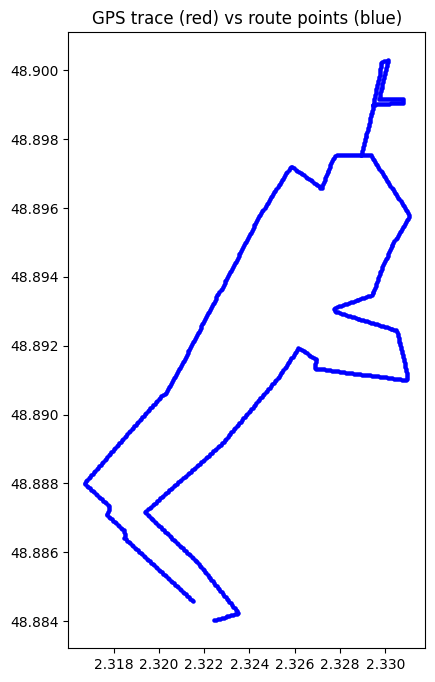

In [20]:
#route_geom = bus_routes[bus_routes['id'] == 14845997708].geometry.iloc[0]
route_geom = bus_routes_interpolated['geometry_dense'].iloc[ridx]

route_points = []
if isinstance(route_geom, LineString):
    route_points = [Point(x, y) for x, y in route_geom.coords]
elif isinstance(route_geom, MultiLineString):
    for line in route_geom.geoms:
        route_points.extend(Point(x, y) for x, y in line.coords)

gdf_route_pts = gpd.GeoDataFrame(geometry=route_points, crs="EPSG:4326")

ax = gdf_route_pts.plot(figsize=(8, 8), color="blue", markersize=5)
#gdf_trace.plot(ax=ax, color="red", markersize=5)
# ax.set_ylim(48.884, 48.888)
# ax.set_xlim(2.320, 2.324)

ax.set_title("GPS trace (red) vs route points (blue)")

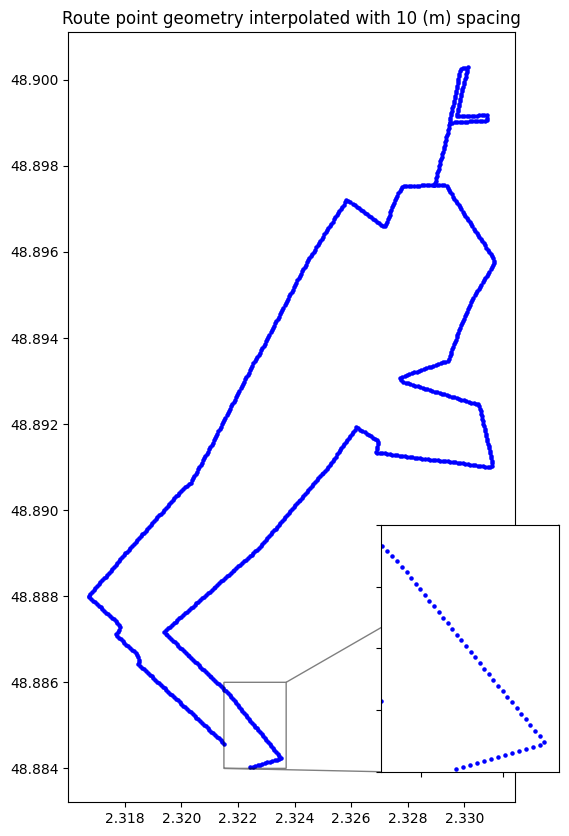

In [21]:
ax = gdf_route_pts.plot(figsize=(10, 10), color="blue", markersize=5)
ax.set_title("Route point geometry interpolated with 10 (m) spacing")

x1, x2 = 2.3215, 2.3237
y1, y2 = 48.884, 48.886

# inset axes (position is [left, bottom, width, height] in axes fraction)
axins = ax.inset_axes(
    [0.7, 0, 0.40, 0.40],
    xlim=(x1, x2),
    ylim=(y1, y2),
    xticklabels=[],
    yticklabels=[],
)

# draw the same data into the inset
gdf_route_pts.plot(ax=axins, color="blue", markersize=5)
# gdf_trace.plot(ax=axins, color="red", markersize=5)

# show rectangle + connectors on main axes
ax.indicate_inset_zoom(axins, edgecolor="black")

plt.show()

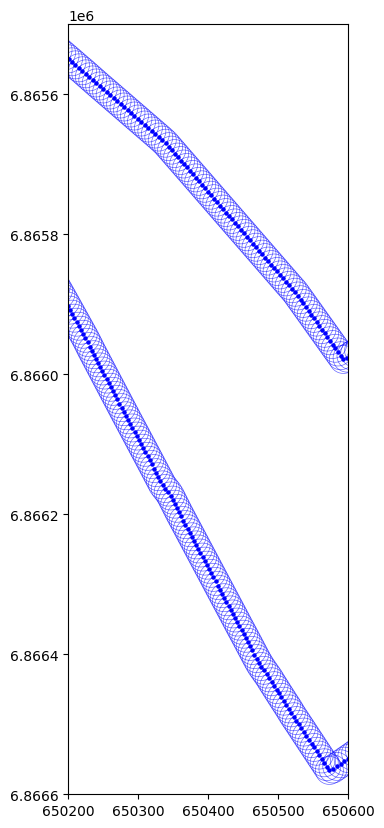

In [23]:
gdf_pts = gdf_route_pts.set_crs("EPSG:4326", allow_override=True)

# project to meters, buffer 20 m
gdf_pts_m = gdf_pts.to_crs(2154)
gdf_circles_m = gdf_pts_m.copy()
gdf_circles_m["geometry"] = gdf_pts_m.geometry.buffer(20)  # 20 meters

fig, ax = plt.subplots(figsize=(10, 10))
gdf_circles_m.plot(ax=ax, facecolor="none", edgecolor="blue", linewidth=0.5, alpha=0.6)
gdf_pts_m.plot(ax=ax, color="blue", markersize=5)
ax.set_ylim(6866600, 6865500)
ax.set_xlim(650200, 650600)
plt.show()

# Visualisation after interpolation

In [2]:
def polish_figure(fig, *,
                  title_size=9,
                  label_size=9,
                  tick_size=8,
                  legend_size=8):
    for ax in fig.axes:
        # Axis titles + labels
        ax.title.set_fontsize(title_size)
        ax.xaxis.label.set_size(label_size)
        ax.yaxis.label.set_size(label_size)

        # Tick labels
        ax.tick_params(axis="both", which="major", labelsize=tick_size)
        ax.tick_params(axis="both", which="minor", labelsize=tick_size)

        # Legend
        leg = ax.get_legend()
        if leg is not None:
            for txt in leg.get_texts():
                txt.set_fontsize(legend_size)
            leg.get_title().set_fontsize(legend_size)

In [3]:
# Load and filter:

df_stats = pd.read_csv("/home/s232534/data/stats_071125/statistical_summary_071125.csv") 
df_map_matching_ip = pd.read_csv("/home/s232534/scripts/map_matching/map_matching_interpolated_percentages.csv") 
#df_percentile_map = pd.read_parquet("/home/s232534/data/percentile_pipeline/percentiles_071125.parquet")

# ---
# Drop modes we will not be using for this thesis and modes to merge and remap:
# ---
modes_to_drop = ['OTHER', 'PLANE', 'ON_DEMAND', 'ELECT_BIKE', 'ELECT_SCOOTER', 'TWO_WHEELER']  
mode_remap = {
    'PRIV_CAR_DRIVER': 'CAR',
    'PRIV_CAR_PASSENGER': 'CAR',
    'LIGHT_COMM_VEHICLE': 'CAR',
    'TAXI': 'CAR',
    'TRAIN_EXPRESS': 'TRAIN'
}

df_stats = functions.remap_and_drop_modes_df(df_stats, mode_remap, modes_to_drop)
df_map_matching_ip = functions.remap_and_drop_modes_df(df_map_matching_ip, mode_remap, modes_to_drop)
#df_percentile_map = functions.remap_and_drop_modes_df(df_percentile_map, mode_remap, modes_to_drop)

# ---
# Filter by speed avg
# ---
threshold: dict = { 
            "WALKING": 6.5, # under 25 km/h
            "BIKE": 10, # 36 km/h
            "CAR": 39,
            "BUS": 14,  # ~50 km/h      
            "TRAMWAY": 19.5,     # ~70 km/h
            "SUBWAY": 11.1, # 40 km/h
            "TRAIN": 61,  # ~ 220 km/h     
        }

df_stats = functions.filter_motion_data_speed_avg(df_stats, threshold)

# ---
# Filter temporal data
# ---
df_stats = functions.filter_temporal_data(df_stats, time_thres=180)

# Propogate the filters down to the map matching df:
keep_ids = set(df_stats['TRIP_KEY'])
df_map_matching_ip = df_map_matching_ip[df_map_matching_ip['TRIP_KEY'].isin(keep_ids)].copy()

# --- 
# Sanity Checks: (should return True and True)
# --- 
print(len(df_stats) == len(df_map_matching_ip))
print(sorted(df_stats['TRIP_KEY']) == sorted(df_map_matching_ip['TRIP_KEY']))

# ---
# Split it out by modality
# ---

# Uni-modal ONLY.
df_stats_s = df_stats.loc[~df_stats['MULTI_MODAL']] 
df_map_matching_ip_s = df_map_matching_ip.loc[~df_map_matching_ip['MULTI_MODAL']] 

# Multi-modal
df_stats_m = df_stats.loc[df_stats['MULTI_MODAL']] 
df_map_matching_ip_m = df_map_matching_ip.loc[df_map_matching_ip['MULTI_MODAL']] 

At WALKING threshold 6.5; 84 are above.
At BIKE threshold 10; 7 are above.
At CAR threshold 39; 8 are above.
At BUS threshold 14; 15 are above.
At TRAMWAY threshold 19.5; 0 are above.
At SUBWAY threshold 11.1; 24 are above.
At TRAIN threshold 61; 8 are above.
Filtered by TOTAL_TIME > 180. Dropped 4705 rows.
True
True


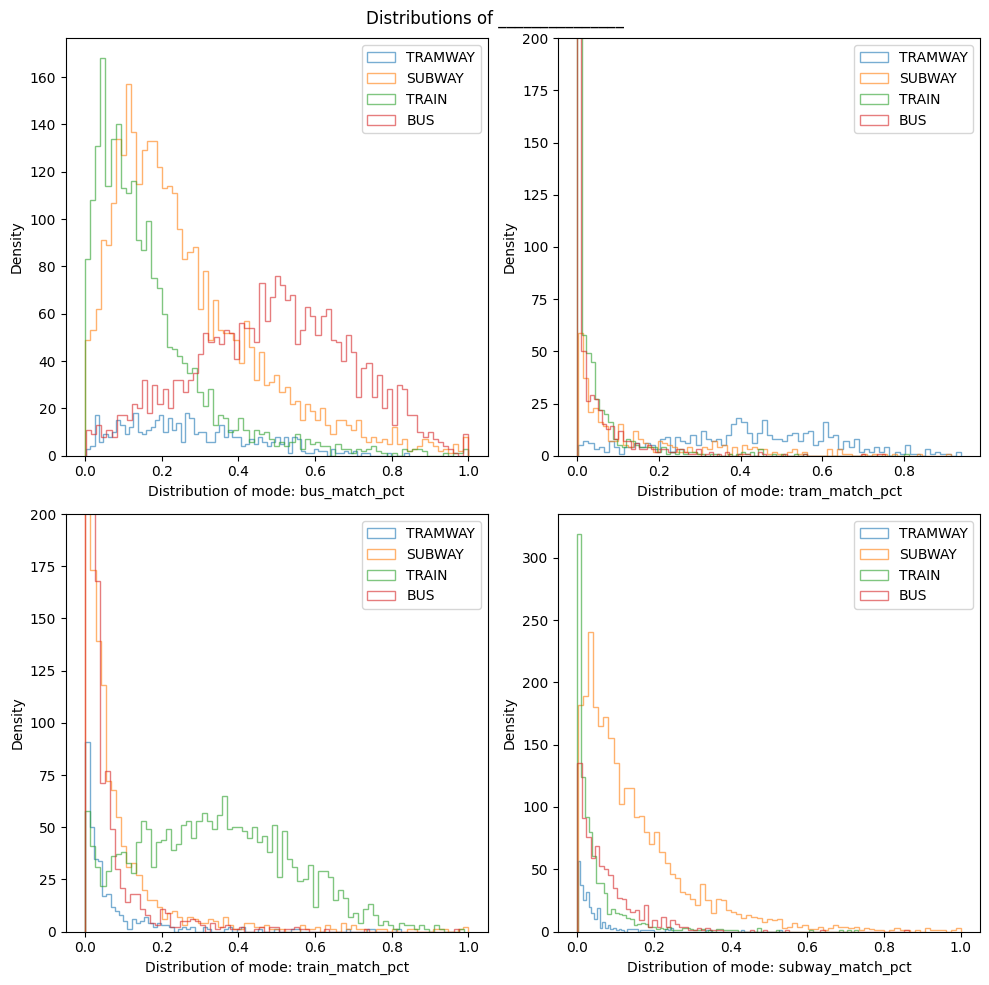

In [6]:
fig, axes = functions.plot_hist_mode_2x2(df=df_map_matching_s, modes=['TRAMWAY', 'SUBWAY', 'TRAIN' ,'BUS'], cols=['bus_match_pct','tram_match_pct','train_match_pct','subway_match_pct'], bin_num=75, PROB_DENSITY=False)
axes[1, 0].set_ylim(0, 200)
axes[0, 1].set_ylim(0, 200)
plt.show()

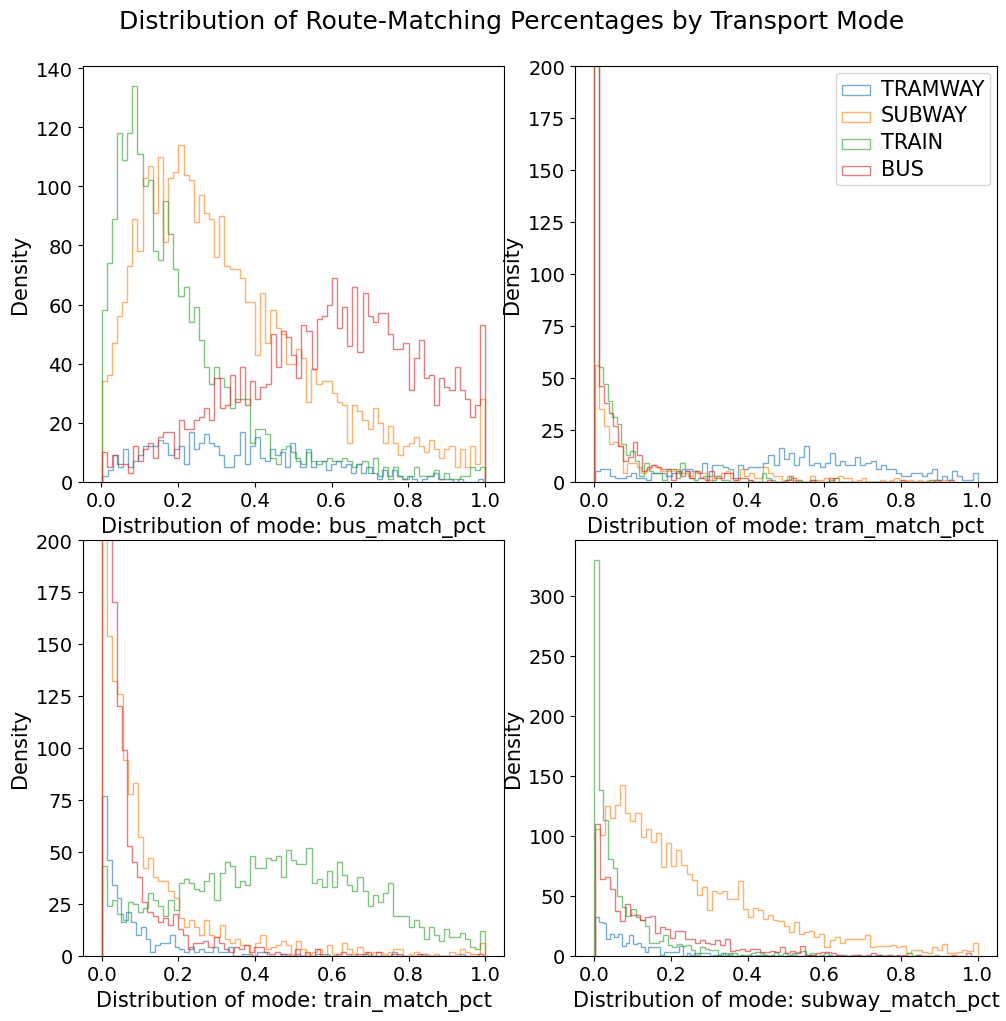

In [10]:
fig, axes = functions.plot_hist_mode_2x2(df=df_map_matching_ip_s, modes=['TRAMWAY', 'SUBWAY', 'TRAIN' ,'BUS'], cols=['bus_match_pct','tram_match_pct','train_match_pct','subway_match_pct'], bin_num=75, PROB_DENSITY=False)
axes[1, 0].set_ylim(0, 200)
axes[0, 1].set_ylim(0, 200)
fig.suptitle("Distribution of Route-Matching Percentages by Transport Mode", fontsize=18, y=1.005)
polish_figure(fig, title_size=16, label_size=15, tick_size=14, legend_size=15)
fig.savefig('route_match_distributions_bin75_singlemode_interpolated.pdf', format='pdf', bbox_inches='tight')
plt.show()

Difference between interpolated results and non-interpolated.

In [142]:
df_map_matching_ip_s.keys()

Index(['KEY', 'bus_match_pct', 'tram_match_pct', 'train_match_pct',
       'subway_match_pct', 'MAIN_MODE', 'MULTI_MODAL', 'MAIN_MODE_ORIG'],
      dtype='object')

In [144]:
for mode in ['BUS', 'SUBWAY', 'TRAIN', 'TRAMWAY']:
    df_mode_ip = df_map_matching_ip_s[df_map_matching_ip_s['MAIN_MODE'] == mode]
    df_mode = df_map_matching_s[df_map_matching_s['MAIN_MODE'] == mode]
    
    # mean (interpolated)
    bus_mean_ip = df_mode_ip['bus_match_pct'].mean()
    tram_mean_ip = df_mode_ip['tram_match_pct'].mean()
    train_mean_ip = df_mode_ip['train_match_pct'].mean()
    subway_mean_ip = df_mode_ip['subway_match_pct'].mean()

    # median (interpolated)
    bus_median_ip = df_mode_ip['bus_match_pct'].median()
    tram_median_ip = df_mode_ip['tram_match_pct'].median()
    train_median_ip = df_mode_ip['train_match_pct'].median()
    subway_median_ip = df_mode_ip['subway_match_pct'].median()

    # mean (non-interpolated)
    bus_mean = df_mode['bus_match_pct'].mean()
    tram_mean = df_mode['tram_match_pct'].mean()
    train_mean = df_mode['train_match_pct'].mean()
    subway_mean = df_mode['subway_match_pct'].mean()

    # median (non-interpolated)
    bus_median = df_mode['bus_match_pct'].median()
    tram_median = df_mode['tram_match_pct'].median()
    train_median = df_mode['train_match_pct'].median()
    subway_median = df_mode['subway_match_pct'].median()

    print(
        mode,
        "\n  interpolated mean   :", {
            "bus": bus_mean_ip,
            "tram": tram_mean_ip,
            "train": train_mean_ip,
            "subway": subway_mean_ip,
        },
        "\n  interpolated median :", {
            "bus": bus_median_ip,
            "tram": tram_median_ip,
            "train": train_median_ip,
            "subway": subway_median_ip,
        },
        "\n  non_interp mean     :", {
            "bus": bus_mean,
            "tram": tram_mean,
            "train": train_mean,
            "subway": subway_mean,
        },
        "\n  non_interp median   :", {
            "bus": bus_median,
            "tram": tram_median,
            "train": train_median,
            "subway": subway_median,
        },
        "\n"
    )

BUS 
  interpolated mean   : {'bus': np.float64(0.5947393700787401), 'tram': np.float64(0.07403195488721805), 'train': np.float64(0.06512044270833334), 'subway': np.float64(0.15657959641255603)} 
  interpolated median : {'bus': np.float64(0.611), 'tram': np.float64(0.025), 'train': np.float64(0.027), 'subway': np.float64(0.108)} 
  non_interp mean     : {'bus': np.float64(0.48828345834978293), 'tram': np.float64(0.06099193548387097), 'train': np.float64(0.04721037253469686), 'subway': np.float64(0.0776329268292683)} 
  non_interp median   : {'bus': np.float64(0.498), 'tram': np.float64(0.0195), 'train': np.float64(0.018), 'subway': np.float64(0.054)} 

SUBWAY 
  interpolated mean   : {'bus': np.float64(0.33247731755424065), 'tram': np.float64(0.18402793296089387), 'train': np.float64(0.12075902864259028), 'subway': np.float64(0.2501360025421036)} 
  interpolated median : {'bus': np.float64(0.281), 'tram': np.float64(0.088), 'train': np.float64(0.059), 'subway': np.float64(0.193)} 
  no

## Signal Generation after densification

In [4]:
import geopandas as gpd
import routes

df_stats = pd.read_csv("/home/s232534/data/stats_071125/statistical_summary_071125.csv", usecols=["TRIP_KEY", "MULTI_MODAL", "MAIN_MODE"])
gps_trace = functions.filter_mode_random(df_stats, 'BUS')

print("Loading route parquet files...")
bus_routes = gpd.read_parquet("/home/s232534/scripts/map_matching/osm_routes/bus_routes.parquet")
bus_routes = routes.add_densified_geometry(bus_routes, spacing_m=10, overwrite_geom=True)

bus_arr = routes.bind_route_geometry_to_id(bus_routes)
BALLTREE_BUS = routes.generate_balltree_obj(bus_arr)

matched_bus = routes.fast_match(bus_arr, gps_trace, BALLTREE_BUS, 20)

# Singal
signal = routes.generate_route_signal(matched_bus, bus_arr, gps_trace, BALLTREE_BUS, 20, verbose=True)

Trip key being sampled = 10_3174-monday-44998-2
Loading route parquet files...


KeyboardInterrupt: 

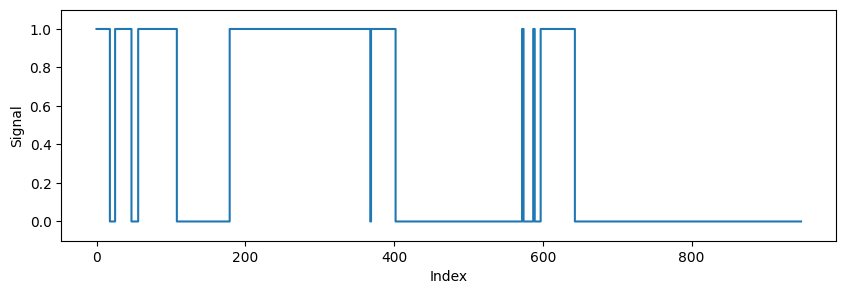

In [11]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 3))
plt.step(np.arange(len(signal)), signal, where="post")
plt.ylim(-0.1, 1.1)
plt.xlabel("Index")
plt.ylabel("Signal")
plt.show()

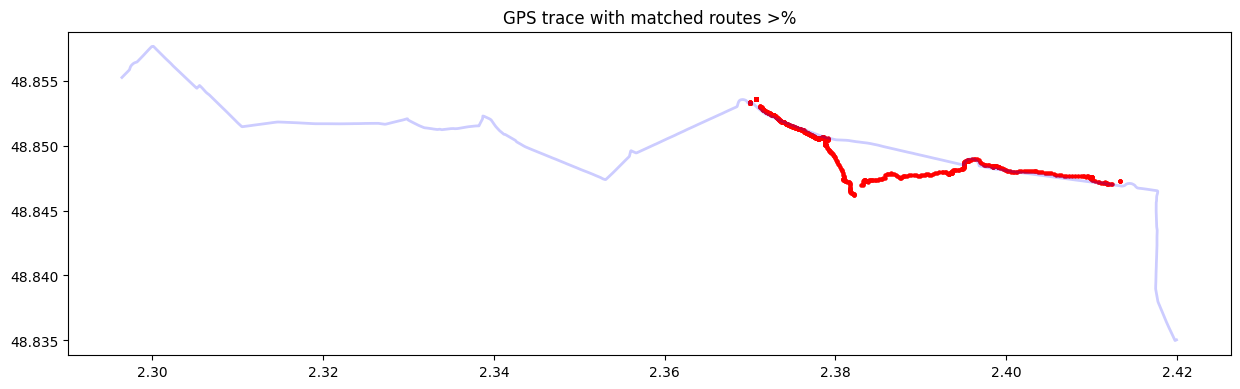

In [13]:
routes.visualise_top_route_ids(gps_trace, bus_routes, [14353120011])

# Further visualisations for the thesis

In [5]:
gps_trace2 = functions.load_trip_by_key("42_0167-tuesday-44873-1")

In [6]:
print("Loading route parquet files...")
bus_routes = gpd.read_parquet("/home/s232534/scripts/map_matching/osm_routes/bus_routes.parquet")
bus_routes_interpolated = routes.add_densified_geometry(bus_routes, 10, overwrite_geom=True)
bus_arr_i = routes.bind_route_geometry_to_id(bus_routes_interpolated)


Loading route parquet files...


In [7]:
BALLTREE_BUS = routes.generate_balltree_obj(bus_arr_i)
matched_bus_i = routes.fast_match(bus_arr_i, gps_trace2, BALLTREE_BUS, 20)

In [19]:
gps_trace2_gdf = gpd.GeoDataFrame(
    gps_trace2[150:-150].copy(),
    geometry=gpd.points_from_xy(gps_trace2["LONGITUDE"][150:-150], gps_trace2["LATITUDE"][150:-150]),
    crs="EPSG:4326",
).to_crs(2154)

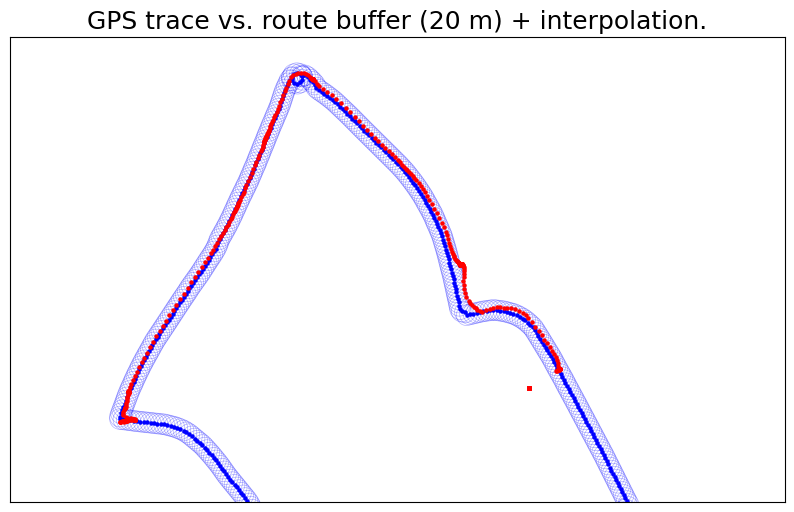

In [27]:
#route_geom = bus_routes[bus_routes['id'] == 5846507111].geometry.iloc[0]
route_geom = bus_routes_interpolated[bus_routes_interpolated['id'] == 5846507111].geometry.iloc[0] # UNCOMMET FOR INTERPOLATED
#route_geom = bus_routes_interpolated['geometry'].iloc[ridx]

route_points = []
if isinstance(route_geom, LineString):
    route_points = [Point(x, y) for x, y in route_geom.coords]
elif isinstance(route_geom, MultiLineString):
    for line in route_geom.geoms:
        route_points.extend(Point(x, y) for x, y in line.coords)

gdf_route_pts = gpd.GeoDataFrame(geometry=route_points, crs="EPSG:4326")


gdf_pts = gdf_route_pts.set_crs("EPSG:4326", allow_override=True)

# project to meters, buffer 20 m
gdf_pts_m = gdf_pts.to_crs(2154)
gdf_circles_m = gdf_pts_m.copy()
gdf_circles_m["geometry"] = gdf_pts_m.geometry.buffer(20)  # 20 meters

fig, ax = plt.subplots(figsize=(10, 10))
gdf_circles_m.plot(ax=ax, facecolor="none", edgecolor="blue", linewidth=0.5, alpha=0.3)
gdf_pts_m.plot(ax=ax, color="blue", markersize=5)
ax.set_ylim(6837500, 6838400)
ax.set_xlim(657500, 659000)

gps_trace2_gdf.plot(ax=ax, color="red", markersize=5)

ax.set_title("GPS trace vs. route buffer (20 m) + interpolation.", fontsize=18)

# Hide the ticks cause it doesn't add anything
ax.set_xticks([])
ax.set_yticks([])
fig.savefig('gps_bus_routebuffered_420167_tuesday_44873-1_interpolated.pdf', format='pdf', bbox_inches='tight')
plt.show()

In [55]:
bus_routes[bus_routes['id'] == 5846507111]

,route,name,operator,id,timestamp,version,tags,osm_type,geometry,ref,changeset
544,bus,Bus 408B : Évry - Bras-de-Fer (circulaire exté...,Tice,5846507111,1657993300,95,"{""colour"":""#00FF00"",""from"":""\u00C9vry - Mairie...",relation,"MULTILINESTRING ((2.42861 48.62474, 2.42862 48...",408,0.0


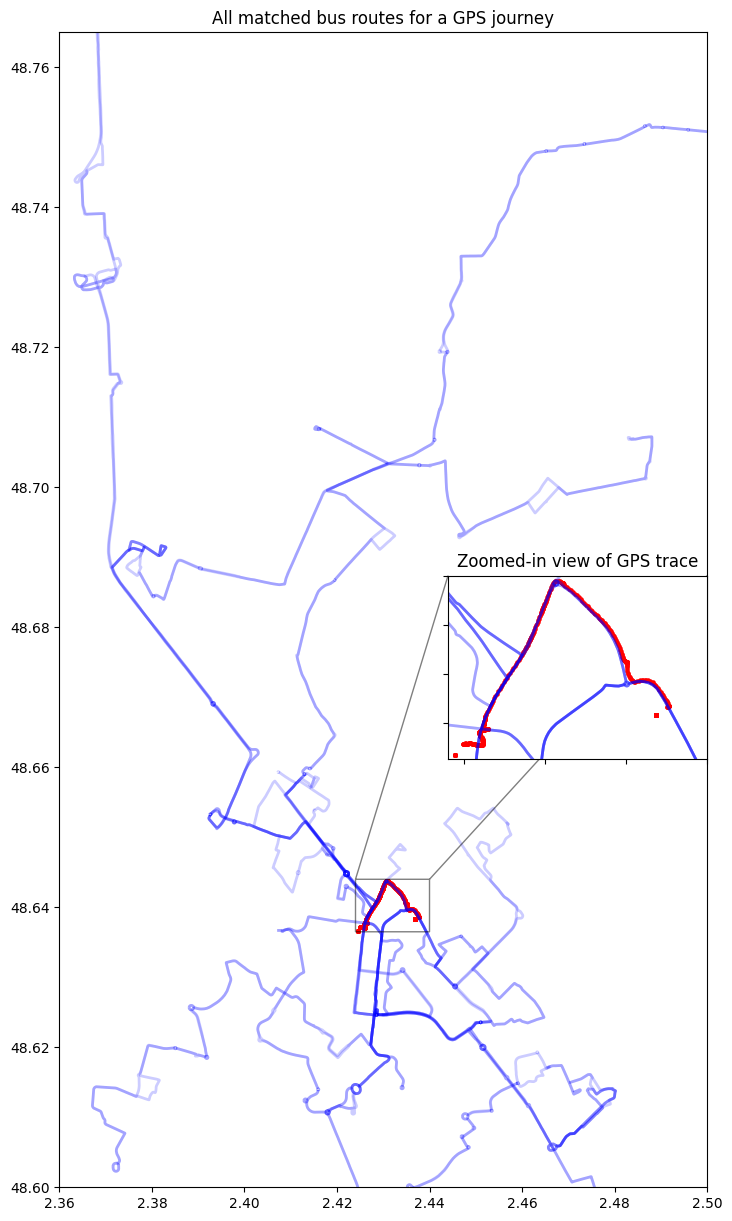

In [89]:
#routes.visualise_top_route_ids(gps_trace2, bus_routes_interpolated, matched_bus_i) 
top_routes = bus_routes_interpolated[bus_routes_interpolated['id'].isin(matched_bus_i)]

gps_trace2 = gpd.GeoDataFrame(gps_trace2, geometry=[Point(x, y) for x, y in zip(gps_trace2['LONGITUDE'], gps_trace2['LATITUDE'])], crs="EPSG:4326")

ax = top_routes.plot(figsize=(15, 15), color="blue", linewidth=2, alpha=0.2)
gps_trace2.plot(ax=ax, color="red", markersize=5)

ax.set_ylim(48.60, 48.765)
ax.set_xlim(2.36, 2.5)

x1, x2 = 2.424, 2.44
y1, y2 = 48.6365, 48.644
axins = ax.inset_axes(
    [0.6, 0.3, 0.40, 0.30],
    xlim=(x1, x2),
    ylim=(y1, y2),
    xticklabels=[],
    yticklabels=[],
)
ax.indicate_inset_zoom(axins, edgecolor="black")
axins.set_title("Zoomed-in view of GPS trace")
top_routes.plot(ax=axins, color="blue", linewidth=2, alpha=0.2)
gps_trace2.plot(ax=axins, color="red", markersize=5)

ax.set_title("All matched bus routes for a GPS journey")
plt.show()

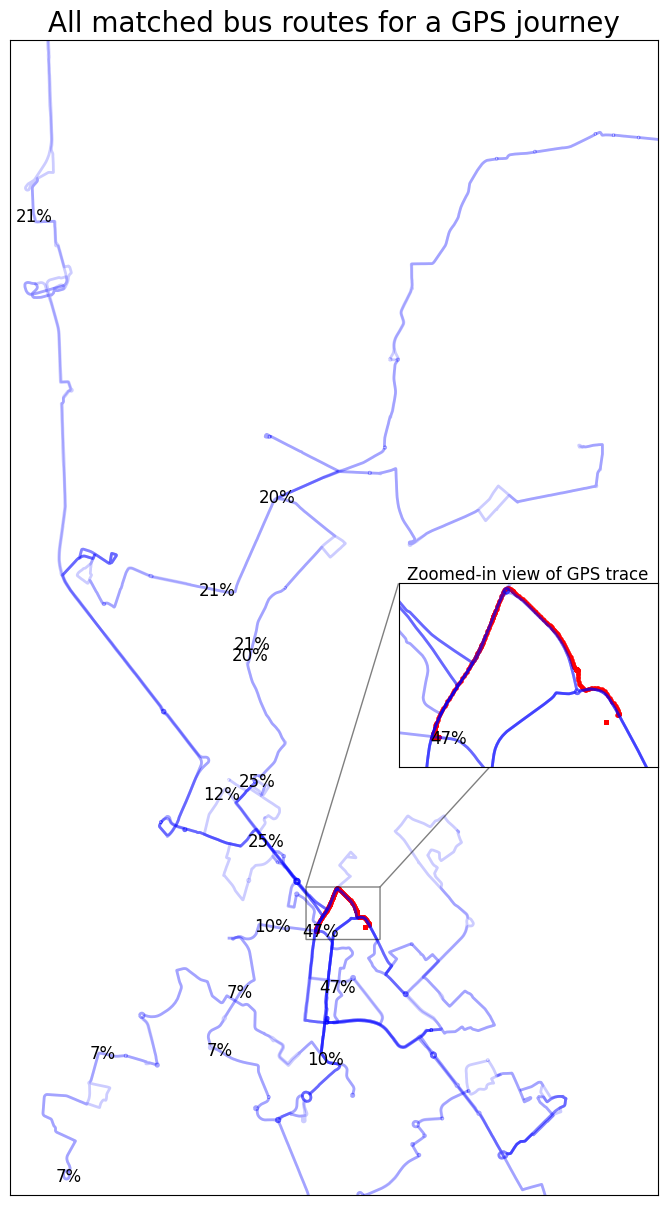

In [41]:
# matched_bus_i is: {route_id: (count, pct)}
top_routes2 = bus_routes_interpolated[bus_routes_interpolated["id"].isin(matched_bus_i)].copy()

# GPS as GeoDataFrame
gps_trace2_gdf = gpd.GeoDataFrame(
    gps_trace2[150:-150],
    geometry=[Point(x, y) for x, y in zip(gps_trace2["LONGITUDE"][150:-150], gps_trace2["LATITUDE"][150:-150])],
    crs="EPSG:4326",
)

# attach match % to each route
top_routes2["match_pct"] = top_routes2["id"].map(lambda rid: matched_bus_i[rid][1])

# --- main plot ---
ax = top_routes2.plot(figsize=(15, 15), color="blue", linewidth=2, alpha=0.2)
gps_trace2_gdf.plot(ax=ax, color="red", markersize=5)

ax.set_xlim(2.36, 2.5)
ax.set_ylim(48.60, 48.765)
ax.set_xticks([]); ax.set_yticks([])
# annotate % on main axis
for _, row in top_routes2.iterrows():
    #p = row.geometry.representative_point()
    p = row.geometry.interpolate(0.2, normalized=True)
    ax.annotate(f"{row.match_pct:.0%}", (p.x, p.y), fontsize=12, color="black", ha="center", va="center")

# --- inset ---
x1, x2 = 2.424, 2.44
y1, y2 = 48.6365, 48.644  

axins = ax.inset_axes([0.6, 0.3, 0.40, 0.30])
top_routes2.plot(ax=axins, color="blue", linewidth=2, alpha=0.2)
gps_trace2_gdf.plot(ax=axins, color="red", markersize=5)

axins.set_xlim(x1, x2)
axins.set_ylim(y1, y2)
axins.set_xticks([]); axins.set_yticks([])
axins.set_title("Zoomed-in view of GPS trace", fontsize=12, pad=2)

# annotate % in inset too
for _, row in top_routes2.iterrows():
    p = row.geometry.interpolate(0.2, normalized=True)
    if (x1 <= p.x <= x2) and (y1 <= p.y <= y2):
        axins.annotate(f"{row.match_pct:.0%}", (p.x, p.y), fontsize=12, color="black", ha="center", va="center")

ax.indicate_inset_zoom(axins, edgecolor="black")

ax.set_title("All matched bus routes for a GPS journey", fontsize=20)
fig = ax.get_figure()
fig.savefig('gps_all_matched_routes.pdf', format='pdf', bbox_inches='tight')
plt.show()

Time to query the BallTree

In [ ]:
import time
EARTH_RADIUS_M = 6371000.0
n_runs = 1000
balltree = BALLTREE_BUS["balltree"]
route_idx = BALLTREE_BUS["route_idx"]

t0 = time.perf_counter()
for _ in range(n_runs):
    gps_deg = gps_trace2[['LATITUDE', 'LONGITUDE']].to_numpy()
    gps_rad = np.radians(gps_deg) 

    rad = 20 / EARTH_RADIUS_M 
    (ind, dist_rad) = balltree.query_radius(gps_rad, r=rad, return_distance=True, sort_results=True) # dist in radians
t1 = time.perf_counter()

avg_time_per_query = (t1 - t0) / n_runs
print(f"Average per single query: {avg_time_per_query} s")

Average per single query: 21657.73 µs


In [99]:
avg_time_per_query

0.021657728746067733

In [100]:
len(gps_trace2)

845